# Ray Data: fit a StandardScaler preprocessor

A Ray Data preprocessor learns column statistics in one pass (fit) and applies them (transform).

**When to use it.** Feature scaling or encoding that must use the same statistics at training and serving time.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Experimental.** The preprocessor transform in this graph uses StandardScaler, which Ray 2.55.1 marks as an alpha API (the picture shows an *alpha* badge on it), so it may change in later Ray releases. The generated code ran on Ray 2.55.1.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

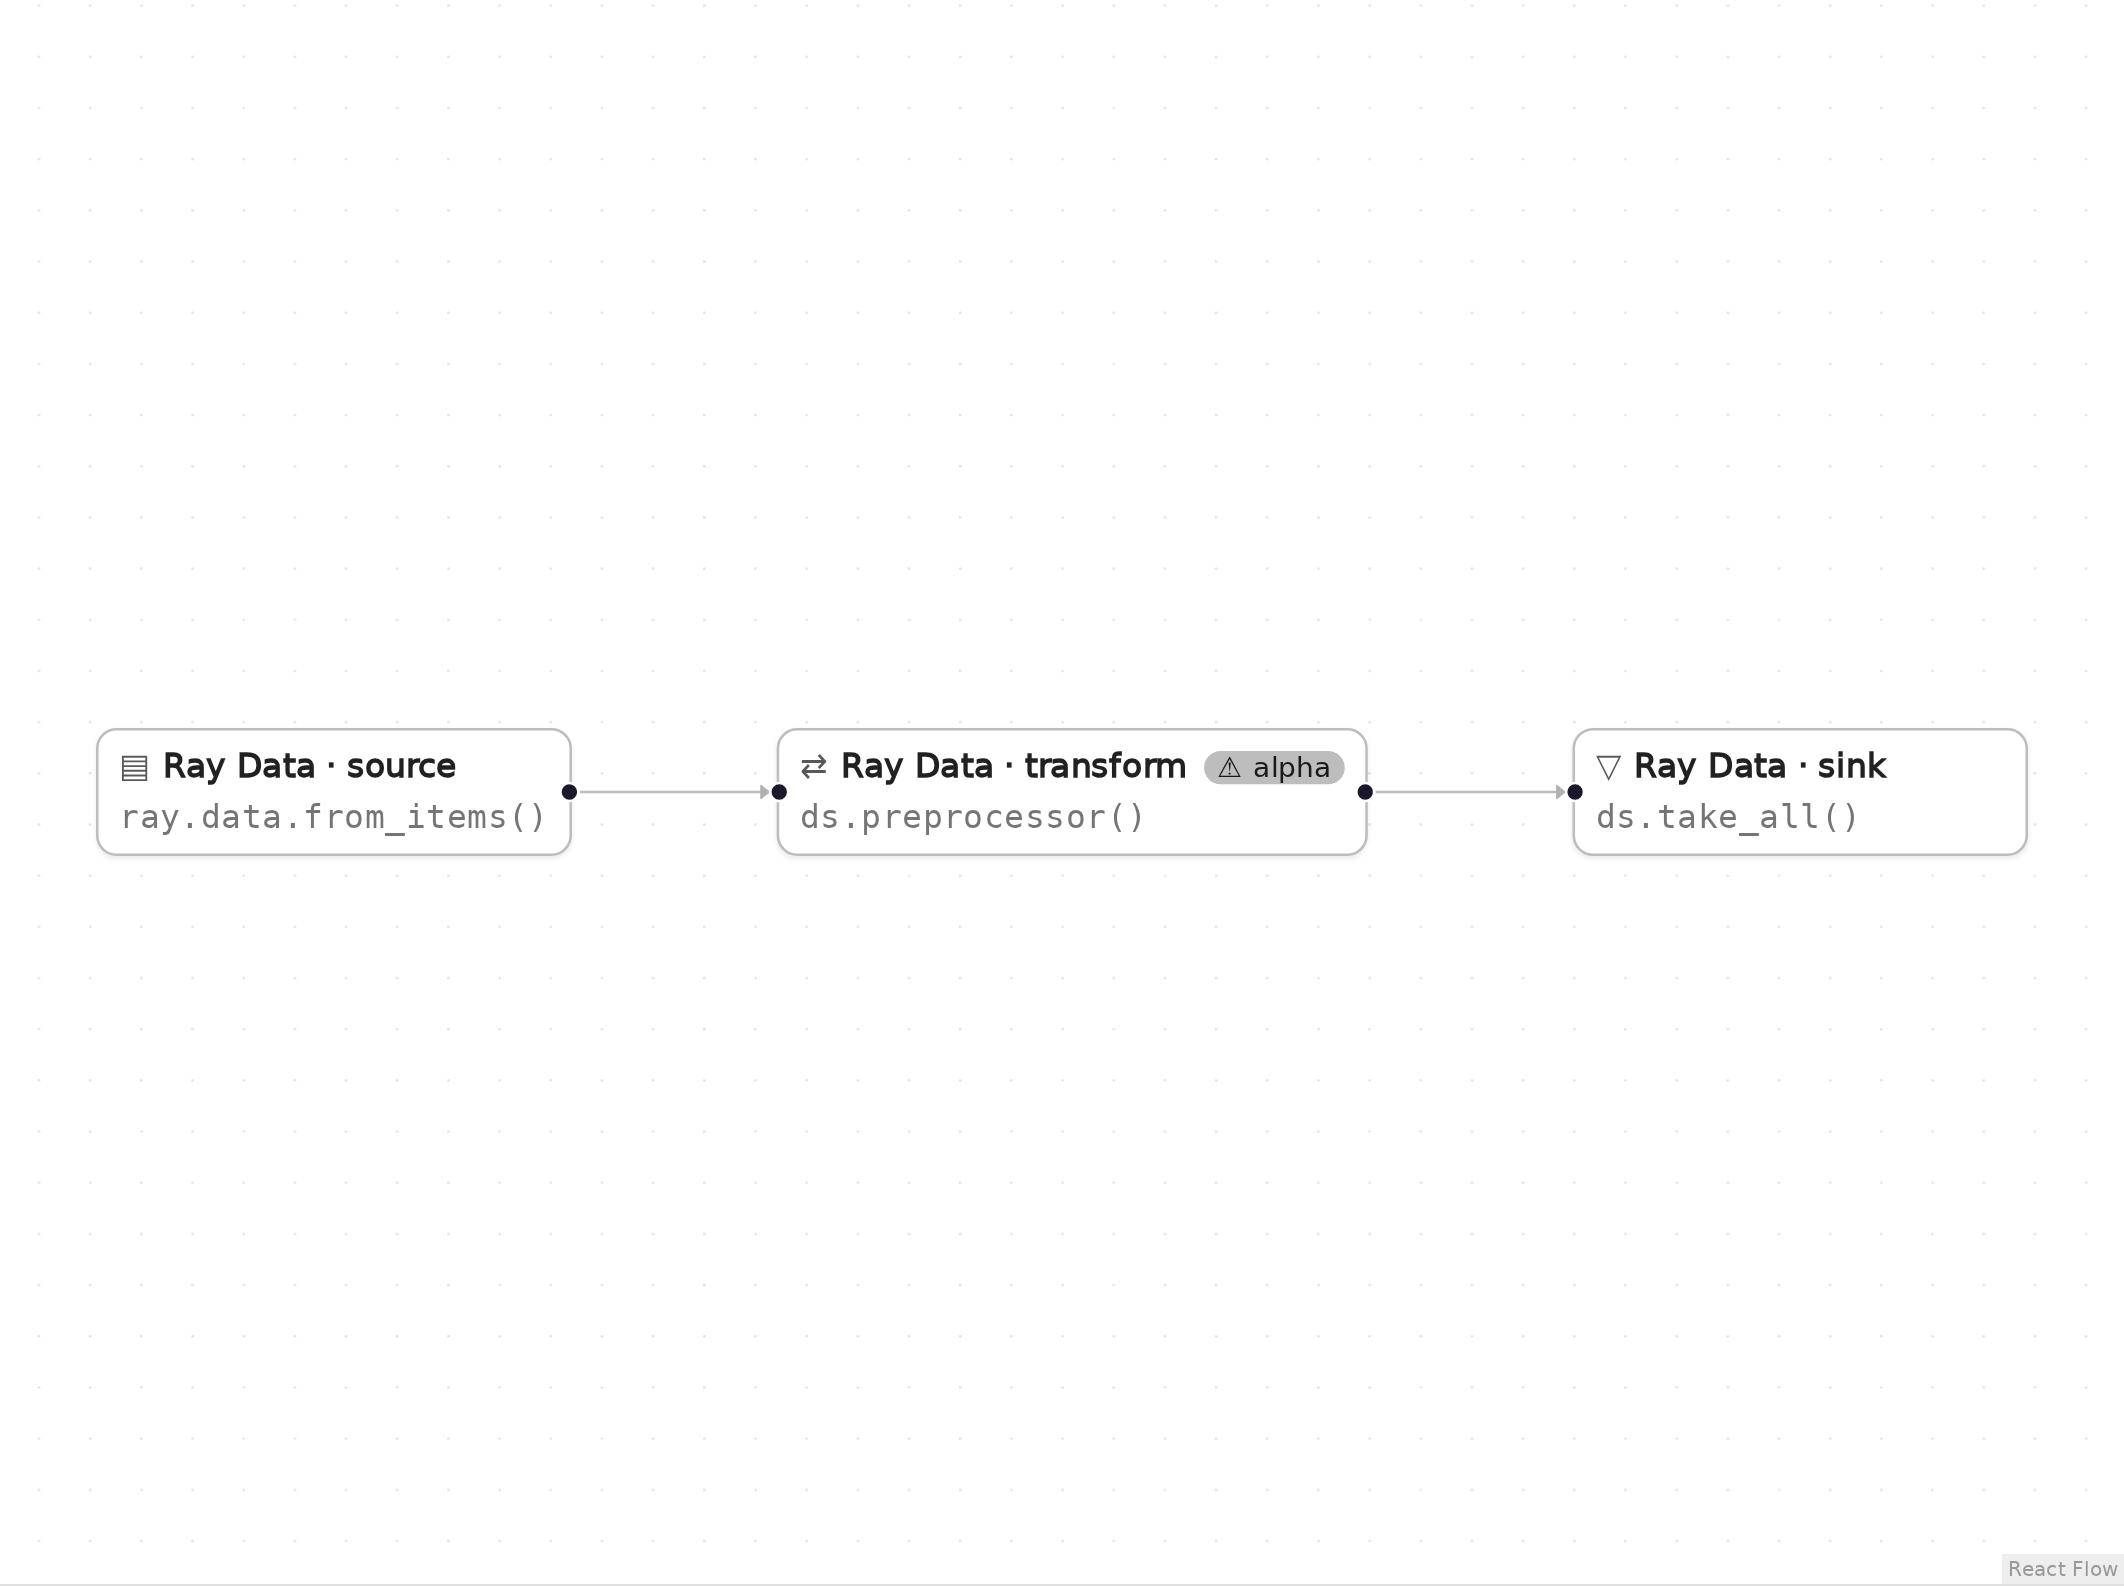

*The graph in Eugo's visual Ray builder.* The node's caption, `ds.preprocessor()`, is the builder's shorthand, not a Ray Dataset method; the real Ray calls are in the generated code below.

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions: StandardScaler is a Ray Data built-in.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray
from ray.data.preprocessors import StandardScaler

if not ray.is_initialized():
    ray.init()

ds = ray.data.from_items([{"x": 1.0}, {"x": 2.0}, {"x": 3.0}])
_prep_n2 = StandardScaler(columns=["x"])
ds = _prep_n2.fit_transform(ds)
scaled = ds.take_all()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
xs = sorted(r["x"] for r in scaled)
assert abs(sum(xs)) < 1e-9, xs
assert abs(xs[2] - 1.224744871391589) < 1e-6, xs
print("scaled x =", xs)

scaled x = [-1.224744871391589, 0.0, 1.224744871391589]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.data.preprocessors import StandardScaler
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 9)

```python
ds = ray.data.from_items([{"x": 1.0}, {"x": 2.0}, {"x": 3.0}])
```

Three rows with a numeric column x.

**Transform** (node `n2`, lines 10–11)

```python
_prep_n2 = StandardScaler(columns=["x"])
ds = _prep_n2.fit_transform(ds)
```

StandardScaler(columns=["x"]).fit_transform(ds) computes the mean and standard deviation, then rescales x to mean 0 and unit variance.

**Sink** (node `n3`, line 12)

```python
scaled = ds.take_all()
```

take_all() returns the scaled rows.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()